In [1]:
import numpy as np 
import torch 
from sklearn.datasets import load_sample_images

In [2]:
sample_images = np.stack(load_sample_images()["images"])
sample_images = torch.tensor(sample_images , dtype=torch.float32) / 255

In [3]:
sample_images.shape

torch.Size([2, 427, 640, 3])

In [4]:
sample_images_permuted = sample_images.permute(0,3,1,2)
sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

In [5]:
import torch.nn as nn 

torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3 ,out_channels=32 , kernel_size=7 ,padding="same" )
fmap = conv_layer(sample_images_permuted)

In [6]:
fmap.shape

torch.Size([2, 32, 427, 640])

In [7]:
conv_layer.weight.shape

torch.Size([32, 3, 7, 7])

In [8]:
conv_layer.bias.shape

torch.Size([32])

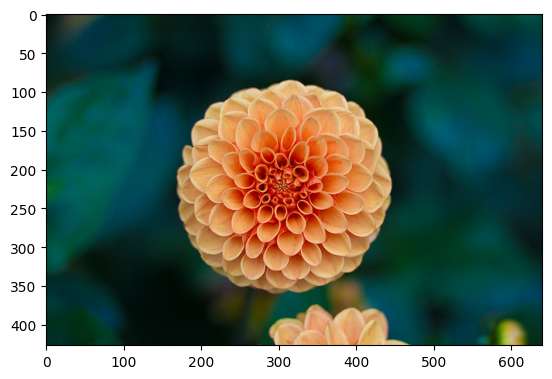

In [9]:
import matplotlib.pyplot as plt

plt.imshow(sample_images[1])

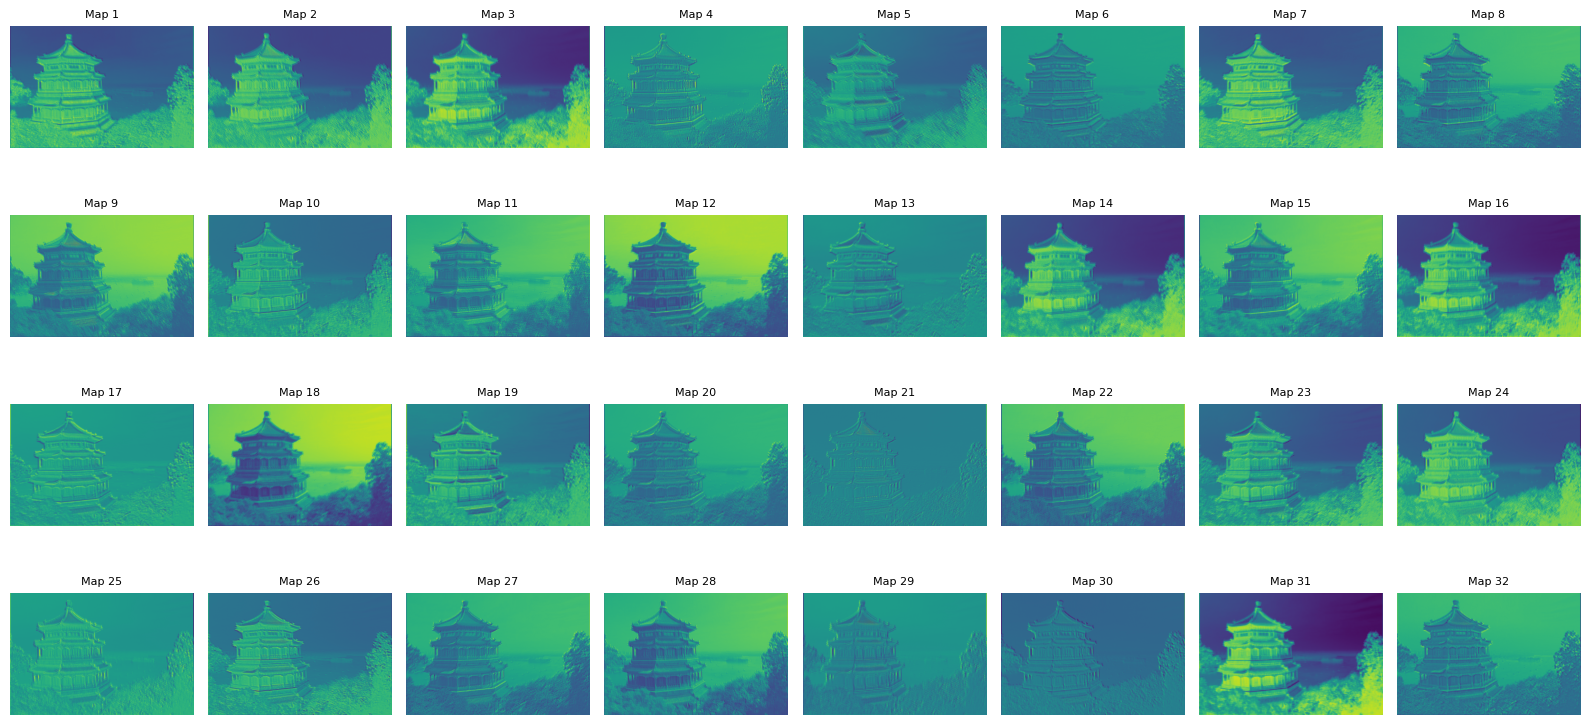

In [10]:
import math
import matplotlib.pyplot as plt

# 1. Detach tensor and convert to numpy array (taking the first sample in the batch)
# Shape goes from (Batch, 32, Height, Width) -> (32, Height, Width)
fmaps_np = fmap[0].detach().cpu().numpy()

num_filters = fmaps_np.shape[0]  # 32

# 2. Setup a grid layout (e.g., 4 rows by 8 columns)
cols = 8
rows = math.ceil(num_filters / cols)  # 32 / 8 = 4 rows

# 3. Create figure with enough space
fig, axes = plt.subplots(rows, cols, figsize=(16, 2 * rows))
axes = axes.flatten()  # Flatten 2D grid to 1D for easy looping

# 4. Plot each feature map
for i in range(num_filters):
    axes[i].imshow(fmaps_np[i], cmap='viridis')
    axes[i].set_title(f"Map {i+1}", fontsize=8)
    axes[i].axis('off')

# Hide any empty subplot slots (if num_filters isn't a multiple of cols)
for j in range(num_filters, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [11]:
##implementing max pooling in pytorch

max_pool = nn.MaxPool2d(kernel_size=2)

In [12]:
import torch.nn.functional as F

class DepthPool(torch.nn.Module):
    def __init__(self, kernel_size, stride=None, padding=0):
        super().__init__()
        self.kernel_size = kernel_size
        self.stride = stride if stride is not None else kernel_size
        self.padding = padding
    def forward(self, inputs):
        batch, channels, height, width = inputs.shape
        Z = inputs.view(batch, channels, height * width)  # merge spatial dims
        Z = Z.permute(0, 2, 1)  # switch spatial and channels dims
        Z = F.max_pool1d(Z, kernel_size=self.kernel_size, stride=self.stride,
        padding=self.padding)  # compute max pool
        Z = Z.permute(0, 2, 1)  # switch back spatial and channels dims
        return Z.view(batch, -1, height, width)  # unmerge spatial dims

In [13]:
from functools import partial

DefaultConv2d = partial(nn.Conv2d, kernel_size=3, padding="same")

model = nn.Sequential(
        DefaultConv2d(in_channels=1, out_channels=64, kernel_size=7), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        DefaultConv2d(in_channels=64, out_channels=128), nn.ReLU(),
        DefaultConv2d(in_channels=128, out_channels=128), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        DefaultConv2d(in_channels=128, out_channels=256), nn.ReLU(),
        DefaultConv2d(in_channels=256, out_channels=256), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        nn.Flatten(),
        nn.Linear(in_features=2304, out_features=128), nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(in_features=128, out_features=64), nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(in_features=64, out_features=10),
)

In [14]:
class ResidualUnit(nn.Module):
    def __init__(self,in_channels , out_channels , stride=1):
        super().__init__()
        DefaultConv2d = partial(nn.Conv2d , kernel_size = 3 , stride=1 , padding=1 ,bias =False)
        self.main_layers = nn.Sequential(
            DefaultConv2d(in_channels , out_channels , stride=stride),
            nn.BatchNorm2d(out_channels), 
            nn.ReLU(),
            DefaultConv2d(out_channels, out_channels),
            nn.BatchNorm2d(out_channels)
        )
        if stride > 1:
            self.skip_connetion = nn.Sequential(
                DefaultConv2d(in_channels , out_channels ,kernal_size = 1 ,stride=stride , padding=0 ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.skip_connetion = nn.Identity()

    def forward(self, input):
        return F.relu(self.main_layers(input) + self.skip_connetion(input))
    

In [15]:
class ResNet34(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [
        nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2,
        padding=3, bias=False),
        nn.BatchNorm2d(num_features=64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        ]
        prev_filters = 64
        for filters in [64] * 3 + [128] * 4 + [256] * 6 + [512] * 3:
            stride = 1 if filters == prev_filters else 2
            layers.append(ResidualUnit(prev_filters, filters, stride=stride))
            prev_filters = filters
        layers += [
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.LazyLinear(10),
            ]
        self.resnet = nn.Sequential(*layers)
    def forward(self, inputs):

        return self.resnet(inputs)

In [20]:
import torchvision
import device
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
model = torchvision.models.convnext_base(weights=weights)


In [21]:
transform = weights.transforms()
preprocessed_images = transform(sample_images_permuted)

In [23]:
model.eval()
with torch.no_grad():
    outputs = model(preprocessed_images)
    print(outputs.shape)


torch.Size([2, 1000])


In [27]:
output = torch.argmax(outputs, dim=1)
output

tensor([698, 985])